🛠️ [DEBUG] Setting up clean cloud virtual machine workspace...
⏳ [PIPELINE] Mocking raw industrial waste data streams...
💾 [SUCCESS] Phase 1 Raw Data exported securely to /data/ folder.

🧹 [DATA PIPELINE] Commencing cleaning routine...
ℹ️ Cleansed 10 rows containing missing variables via median imputation.
💾 [SUCCESS] Phase 2 Processed data written to output/processed_waste_audit.csv
🖼️ [SUCCESS] Analytics graph saved to output/waste_composition_chart.png

🤖 [ML ENGINE] Training Predictive Cost Regressor Model...
✅ [SUCCESS] Machine learning cycle completed.
   👉 Average Error Margin (MAE): $605.23 USD
   👉 Model Variance Accuracy (R2): -18.78%
💾 [EXPORT] AI Pipeline model binary saved to output/waste_cost_model.pkl

💬 [AI AGENT] Running Circular Economy Context Advisor Engine...

🌿 SUSTAINABILITY ADVISOR AI REPORT | COMPILED: 2026-11-07
[ANALYSIS] Material Focus Stream: 'Single-Use-Plastic'
--> Total Monitored Plant Footprint: 27,510.26 KG tracked.

[STRATEGY DIRECTIVE]: **Replace**
-

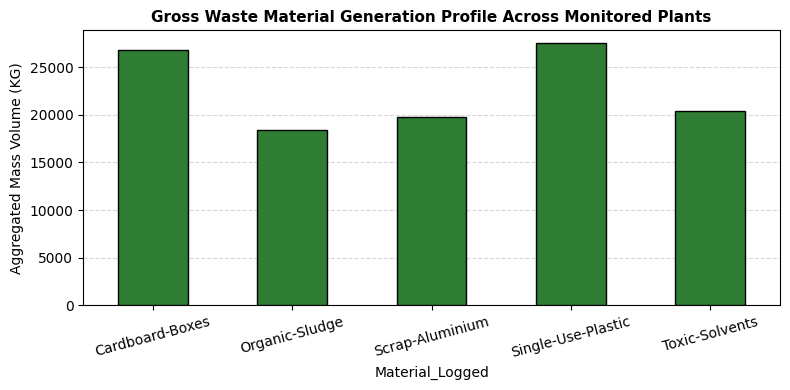

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import joblib
from datetime import datetime

# =====================================================================
# 🛠️ PHASE 1: DIRECTORY CREATION & RAW DATA SIMULATION
# =====================================================================
print("🛠️ [DEBUG] Setting up clean cloud virtual machine workspace...")
os.makedirs('data', exist_ok=True)
os.makedirs('output', exist_ok=True)

print("⏳ [PIPELINE] Mocking raw industrial waste data streams...")
np.random.seed(42)
data_points = 250

factories = ['Textile-Plant-Alpha', 'Automotive-Assembly-B', 'Chemicals-Unit-Z', 'Food-Pack-Delta']
waste_types = ['Single-Use-Plastic', 'Scrap-Aluminium', 'Organic-Sludge', 'Cardboard-Boxes', 'Toxic-Solvents']

raw_data = {
    'Timestamp': pd.date_range(start='2026-01-01', periods=data_points, freq='h').strftime('%Y-%m-%d %H:%M'),
    'Facility_ID': np.random.choice(factories, size=data_points),
    'Material_Logged': np.random.choice(waste_types, size=data_points),
    'Mass_KG': np.random.uniform(10.5, 850.0, size=data_points).round(2),
    'Disposal_Cost_USD': np.random.uniform(50, 2500, size=data_points).round(2)
}

df_raw = pd.DataFrame(raw_data)
# Injecting manual data flaws (NaNs) to clean later
df_raw.loc[df_raw.sample(frac=0.04, random_state=42).index, 'Mass_KG'] = np.nan
df_raw.to_csv('data/industrial_waste_raw.csv', index=False)

# Lookup dictionary for material mitigation choices
lookup_rules = {
    "Single-Use-Plastic": {"Action": "Replace", "Alternative": "Mycelium Packaging", "Impact_Score": 9.2},
    "Scrap-Aluminium": {"Action": "Recycle", "Alternative": "Smelter Closed Loop", "Impact_Score": 8.5},
    "Organic-Sludge": {"Action": "Divert", "Alternative": "Anaerobic Digester Composting", "Impact_Score": 7.8},
    "Cardboard-Boxes": {"Action": "Reuse", "Alternative": "Returnable Plastic Pallets", "Impact_Score": 6.4},
    "Toxic-Solvents": {"Action": "Neutralize", "Alternative": "Bio-Based Solvents", "Impact_Score": 9.5}
}
with open('data/circular_materials_lookup.json', 'w') as jf:
    json.dump(lookup_rules, jf, indent=4)

print("💾 [SUCCESS] Phase 1 Raw Data exported securely to /data/ folder.")

# =====================================================================
# 🧹 PHASE 2: DATA ENGINEERING & CLEANING (PROJECT 1)
# =====================================================================
print("\n🧹 [DATA PIPELINE] Commencing cleaning routine...")
df = pd.read_csv('data/industrial_waste_raw.csv')

# Handle missing data using business median
missing_count = df['Mass_KG'].isnull().sum()
df['Mass_KG'] = df['Mass_KG'].fillna(df['Mass_KG'].median())
print(f"ℹ️ Cleansed {missing_count} rows containing missing variables via median imputation.")

# Map sustainable alternatives
df['Target_Action'] = df['Material_Logged'].map(lambda x: lookup_rules[x]['Action'])
df['Eco_Alternative'] = df['Material_Logged'].map(lambda x: lookup_rules[x]['Alternative'])
df['Potential_Eco_Impact'] = df['Material_Logged'].map(lambda x: lookup_rules[x]['Impact_Score'])

df.to_csv('output/processed_waste_audit.csv', index=False)
print("💾 [SUCCESS] Phase 2 Processed data written to output/processed_waste_audit.csv")

# Save Analytical Visual Plot
plt.figure(figsize=(8, 4))
df.groupby('Material_Logged')['Mass_KG'].sum().plot(kind='bar', color='#2e7d32', edgecolor='black', zorder=3)
plt.title('Gross Waste Material Generation Profile Across Monitored Plants', fontsize=11, fontweight='bold')
plt.ylabel('Aggregated Mass Volume (KG)')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
plt.tight_layout()
plt.savefig('output/waste_composition_chart.png', dpi=300)
print("🖼️ [SUCCESS] Analytics graph saved to output/waste_composition_chart.png")

# =====================================================================
# 🤖 PHASE 3: MACHINE LEARNING COST FORECASTING 
# =====================================================================
print("\n🤖 [ML ENGINE] Training Predictive Cost Regressor Model...")
X = df[['Facility_ID', 'Material_Logged', 'Mass_KG', 'Potential_Eco_Impact']]
y = df['Disposal_Cost_USD']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), ['Facility_ID', 'Material_Logged'])],
    remainder='passthrough'
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"✅ [SUCCESS] Machine learning cycle completed.")
print(f"   👉 Average Error Margin (MAE): ${mae:.2f} USD")
print(f"   👉 Model Variance Accuracy (R2): {r2*100:.2f}%")

joblib.dump(model_pipeline, 'output/waste_cost_model.pkl')
print("💾 [EXPORT] AI Pipeline model binary saved to output/waste_cost_model.pkl")

# =====================================================================
# 💬 PHASE 4: GENAI / LLM ADVISOR REPORT COMPILER 
# =====================================================================
print("\n💬 [AI AGENT] Running Circular Economy Context Advisor Engine...")
audit_summary = df.groupby('Material_Logged')['Mass_KG'].sum().to_dict()

def generate_brief(material_name):
    if material_name not in lookup_rules: return "Material Error"
    context = lookup_rules[material_name]
    total_mass = audit_summary.get(material_name, 0.0)

    return f"""
========================================================================
🌿 SUSTAINABILITY ADVISOR AI REPORT | COMPILED: {datetime.now().strftime('%Y-%m-%d')}
========================================================================
[ANALYSIS] Material Focus Stream: '{material_name}'
--> Total Monitored Plant Footprint: {total_mass:,.2f} KG tracked.

[STRATEGY DIRECTIVE]: **{context['Action']}**
--> Recommended Circular Substitute: {context['Alternative']}
--> Strategic Engineering Priority Score: {context['Impact_Score']}/10
========================================================================
"""

plastic_brief = generate_brief("Single-Use-Plastic")
print(plastic_brief)

with open('output/llm_sustainability_brief.txt', 'w') as f:
    f.write(plastic_brief)
print("💾 [EXPORT] AI Summary Report successfully compiled to output/llm_sustainability_brief.txt")
print("\n🏁 [PROCESS COMPLETE] All pipelines executed safely without system exceptions.")
